# River — streaming machine learning

This notebook is an updated version of the original demo, aligned with **River 0.26.1**.

> **Environment:** River 0.26.1 requires Python **3.11+**. The examples below use the current River API and avoid relying on stale notebook outputs.

If River is not installed yet, run the optional installation cell below.


In [16]:
# Optional installation:
!pip install -U "river==0.26.1"
#!pip install graphviz
!pip install scikit-learn
import sys
from importlib.metadata import PackageNotFoundError, version

print(f"Python: {sys.version.split()[0]}")

try:
    print(f"River:  {version('river')}")
except PackageNotFoundError:
    print("River is not installed. Uncomment the %pip line above and run this cell again.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 9.7 MB/s  0:00:00m eta 0:00:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Python: 3.12.3
River:  0.26.1


# PART I. Using `river`

## From batch to stream learning
---

Traditional machine learning follows a sequence of steps. A minimal pipeline includes:

1. Data preprocessing (cleanup, filtering, feature engineering, etc.)
2. Training (create a model from the data)
3. Testing (use the model to obtain predictions)

This approach assumes that **all** the data is available for training and data is processed in **batches**.

Let's see an example based on the [`Iris` dataset](https://scikit-learn.org/stable/auto_examples/datasets/plot_iris_dataset.html) available in `scikit-learn`:

> This data set consists of 3 different types of irises’ (Setosa, Versicolour, and Virginica) petal and sepal length, stored in a 150x4 numpy.ndarray

In [14]:
from sklearn import datasets as skdatasets
from sklearn.naive_bayes import GaussianNB as GaussianNBSKL
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

iris = skdatasets.load_iris()
x = iris.data
y = iris.target

The `load_iris()` returns the data set and related information. Data features and the corresponding targets (classification labels) are accessible via the `data` and `target` properties respectively.

We can assume that the data has been already preprocessed. We need to split the dataset into $train$ and $test$ sets where $train \notin test$. We can use the `train_test_split` method as follows:

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, stratify=iris.target, random_state=42
)

In [7]:
print(f'Shape (n_rows, n_cols) of X: {iris.data.shape}, '
      f'X_train: {X_train.shape}, X_test: {X_test.shape}')

Shape (n_rows, n_cols) of X: (150, 4), X_train: (105, 4), X_test: (45, 4)


Now we proceed with the model training. In this example, we will train a Gaussian Naive Bayes model (`GaussianNB`).

In [8]:
model = GaussianNBSKL()
model.fit(X=X_train, y=y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[35.,35.,35.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,3.153e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 4)","[[4.99,3.43,1.49,0.24], [5.95,2.73,4.24,1.31], [6.68,3.01,5.63,2.07]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 4)","[[0.1 ,0.17,0.02,0.01], [0.24,0.09,0.21,0.04], [0.42,0.12,0.32,0.06]]"


And we use the trained model to get predictions:

In [9]:
y_pred = model.predict(X=X_test)

`y_pred` contains the predicted class labels for each sample in `X_test`. Since we know the true labels for these samples (`y_test`) we can evaluate the performance of the model. In this case, we will use the `accuracy_score` method:

In [10]:
print(f'Model accuracy: {accuracy_score(y_test, y_pred):.4f}')

Model accuracy: 0.9111


The trained model has an accuracy of ~91%, which is decent considering the simplicity of the dataset.

As mentioned, batch methods expect **all the data** available for training. However, in multiple real-world applications, this requirement is difficult to meet, especially in dynamic environments that constantly generate data.

A common way to address this situation is to collect data over time and generate new models. However, this presents additional challenges:

- Should we train new models on new data only or extend the old data?
- How much new data is enough to trigger the creation of a new model?
- Is the new model better than the old one?
- Storing all data might be unfeasible or impractical in some cases (e.g. financial markets)
- ...

### Stream learning

A data stream is an infinite sequence of elements. Stream learning methods are specially designed to learn from data streams. Streaming models adhere to a set of requirements:

- **Process the data one sample at a time**. A sample is seen only once and it is gone after processing.
- **Be efficient**. Resources are limited (memory, time) but streams are infinite.
- **Predict at any time**. Models continually learn and provide predictions at any point in the stream.

A streaming model **updates** its internal state as it processes the data stream.

We can simulate a data stream from the previous example by "looping" over the data *one sample at a time* as follows:

In [11]:
for xi, yi in zip(X_train, y_train):
    # Here is where learning takes place
    pass

xi, yi    # last data sample

(array([4.6, 3.1, 1.5, 0.2]), np.int64(0))

Notice that the data is encoded in `numpy.ndarrays`, an efficient data structure when dealing with large 2D data.

In `river`, data is represented as `dict`. Dictionaries are fast to process 1D data and elements are easily accessible 'by key'.

Before using this data in `river` we must transform it. This is easily done in Python:

In [12]:
for xi, yi in zip(X_train, y_train):
    x = dict(zip(iris.feature_names, xi))

x, yi

({'sepal length (cm)': np.float64(4.6),
  'sepal width (cm)': np.float64(3.1),
  'petal length (cm)': np.float64(1.5),
  'petal width (cm)': np.float64(0.2)},
 np.int64(0))

In our previous example, we trained a Gaussian Naive Bayes model using the implementation from `scikit-learn`. The Naive Bayes method is an **incremental method**.

A small number of [incremental methods](https://scikit-learn.org/stable/modules/computing.html#scaling-with-instances-using-out-of-core-learning) are available in `scikit-learn`. These methods provide a `partial_fit` method for incremental training using *mini-batches*.

In the following example, we will use the implementation of `GaussianNB` from `river`.

In `river`, training and predicting are performed via the `learn_one` and `predict_one` methods.

In [17]:
from river.naive_bayes import GaussianNB

model = GaussianNB()
for xi, yi in zip(X_train, y_train):
    x = dict(zip(iris.feature_names, xi))
    model.learn_one(x=x, y=yi)              # Train the model

y_pred = []
for xi in X_test:
    x = dict(zip(iris.feature_names, xi))
    y_pred.append(model.predict_one(x=x))   # Predict class-label

The model's predictions are in `y_pred`. Again, we measure the accuracy of the model by comparing predictions to the ground truth:

In [18]:
print(f'Model accuracy: {accuracy_score(y_test, y_pred):.4f}')

Model accuracy: 0.9111


Hurray! We got the same performance from the model trained one sample at a time...

But wait, this is NOT different from the "batch" setting. We are still doing "training" and then "testing" using two "for" loops.

In the streaming setting, training and predicting happen inside a single loop. Remember, a data sample is available only once in the stream.

To simplify our code, we can use the `iter_sklearn` method to convert a `scikit-learn` dataset object into an iterable that returns the data as `dict`.

In [19]:
from river.stream import iter_sklearn_dataset

y_pred = []
y_true = []

model = GaussianNB()

for x, y in iter_sklearn_dataset(iris, shuffle=True, seed=42):
   y_p = model.predict_one(x)   # Predict class-label
   model.learn_one(x, y)        # Train the model
   if y_p is None:              # Process next sample if the model is empty
       continue
   y_pred.append(y_p)
   y_true.append(y)

print(f'Model accuracy: {accuracy_score(y_true, y_pred):.4f}')

Model accuracy: 0.9195


This time we have successfully implemented a stream learning task. This is known as **prequential evaluation** or **interleaved test-then-train** evaluation. 

Notice the *order* of the training and prediction operations. When a new data sample ($x_i$, $y_i$) arrives:

1. Predict the label ($y_i'$) for the new data sample ($x_i$), not "seen" by the model yet
2. Train the model using the new sample ($x_i$, $y_i$)

This **order matters**!

A benefit from this approach is that we can use *all* labeled samples in the stream to measure a model's performance. Notice that the model provides predictions at any point in the stream, depending on its current internal state. Batch methods can only predict after they finished training.

In the previous code snippet, we used two auxiliary variables to store the true labels and the predicted labels. This is because `accuracy_score` requires access to all the data. However, storing all the true and predicted labels from a data stream is *impractical*.

In `river`, all methods can be updated one single sample at a time, including performance metrics! Let's see how to update a metric.

In [20]:
from river.metrics import Accuracy

metric = Accuracy()
for yt, yp in zip(y_true, y_pred):
    metric.update(y_true=yt, y_pred=yp)
metric

Accuracy: 91.95%

The `update` method takes true and predicted pairs and updates the metric. We can compare the confusion matrices:

In [21]:
print("Confusion matrix from all data:")
print(confusion_matrix(y_true, y_pred))
print("Confusion matrix from updatable metric:")
print(metric.cm)


Confusion matrix from all data:
[[48  1  0]
 [ 2 46  2]
 [ 0  7 43]]
Confusion matrix from updatable metric:
    0    1    2   
0   48    1    0  
1    2   46    2  
2    0    7   43  


Now we can rewrite our example.

In [22]:
model = GaussianNB()
metric = Accuracy()
n_samples = 0

for x, y in iter_sklearn_dataset(iris, shuffle=True, seed=42):
    y_pred = model.predict_one(x)

    if y_pred is not None:
        metric.update(y_true=y, y_pred=y_pred)

    model.learn_one(x, y)
    n_samples += 1

print(f"{n_samples} samples processed.")
print(metric)


150 samples processed.
Accuracy: 91.95%


### The `progressive_val_score` method

For convenience, the `progressive_val_score` method implements the prequential evaluation. It requires three components: 

- a data stream
- a model
- a metric

In [23]:
from river.evaluate import progressive_val_score

# Setup stream and estimators
stream = iter_sklearn_dataset(iris, shuffle=True, seed=42)
nb = GaussianNB()
metric = Accuracy()

# Setup evaluator
progressive_val_score(dataset=stream, model=nb, metric=metric, print_every=10)

[10] Accuracy: 44.44%
[20] Accuracy: 73.68%
[30] Accuracy: 82.76%
[40] Accuracy: 84.62%
[50] Accuracy: 85.71%
[60] Accuracy: 88.14%
[70] Accuracy: 88.41%
[80] Accuracy: 89.87%
[90] Accuracy: 89.89%
[100] Accuracy: 90.91%
[110] Accuracy: 91.74%
[120] Accuracy: 92.44%
[130] Accuracy: 92.25%
[140] Accuracy: 92.81%
[150] Accuracy: 91.95%


Accuracy: 91.95%

## Decision trees for data streams
---

### `NEWeather` dataset

**Description:** The National Oceanic and Atmospheric Administration (NOAA),
has compiled a database of weather measurements from over 7,000 weather 
stations worldwide. Records date back to the mid-1900s. Daily measurements
include a variety of features (temperature, pressure, wind speed, etc.) as
well as a series of indicators for precipitation and other weather-related
events. The `NEweather` dataset contains data from this database, specifically
from the Offutt Air Force Base in Bellevue, Nebraska ranging for over 50 years
(1949-1999).

**Features:** 8 Daily weather measurements
 
|       Attribute      | Description |
|:--------------------:|:-----------------------------|
| `temp`                   | Temperature
| `dew_pnt`                | Dew Point
| `sea_lvl_press`          | Sea Level Pressure
| `visibility`             | Visibility
| `avg_wind_spd`           | Average Wind Speed
| `max_sustained_wind_spd` | Maximum Sustained Wind Speed
| `max_temp`               | Maximum Temperature
| `min_temp`               | Minimum Temperature


**Class:** `rain` | 0: no rain, 1: rain
 
**Samples:** 18,159

---

In this example, we load the data from a csv file with `pandas.read_csv`. 

Next, we use the `iter_pandas` utility method to iterate over the `DataFrame`. The model in this example is a `HoeffdingTreeClassifier`, a type of decision tree designed for data streams.

In [24]:
import pandas as pd

from river.stream import iter_pandas
from river.tree import HoeffdingTreeClassifier
from river.datasets import WaterFlow

data = pd.read_csv("NEweather.csv")
print(data)
features = data.columns[:-2]
stream = iter_pandas(X=data[features], y=data['rain'])

model = HoeffdingTreeClassifier()
metric = Accuracy()

progressive_val_score(dataset=stream,
                      model=model,
                      metric=metric,
                      print_every=1000)

       temp  dew_pnt  sea_lvl_press  visibility  avg_wind_spd  \
0      19.8     14.0         1019.6         8.4           9.9   
1      26.8     22.2         1006.2         8.1          10.9   
2      34.6     32.9         1004.6         3.9          13.8   
3      26.4     21.5         1006.9         8.0          18.7   
4      14.7      7.9         1009.9         8.1          14.1   
...     ...      ...            ...         ...           ...   
18154  32.6     21.9         1022.7         7.0          12.4   
18155  36.8     25.4         1014.9         7.0          10.0   
18156  41.9     29.9         1010.0         7.0           4.7   
18157  42.4     29.7         1011.3         7.0           3.3   
18158  36.6     29.5         1017.9         6.8           4.8   

       max_sustained_wind_spd  max_temp  min_temp  rain  
0                        15.9      28.9      14.0     0  
1                        19.0      34.0      21.0     0  
2                        22.0      36.0      

Accuracy: 74.15%

## Pipelines
---

Pipelines are powerful tools that "chain" a sequence of operations. 

For example, logistic regression is sensitive to the scale of the features. Rescaling the data so that each feature has mean $\mu=0$ and variance $\sigma^2=1$ is generally considered good practice.

We can apply the rescaling and fit the logistic regression sequentially in an elegant manner using a Pipeline.


In [26]:
from river import compose, linear_model, preprocessing

data = pd.read_csv("NEweather.csv")
features = data.columns[:-2]
stream = iter_pandas(X=data[features], y=data["rain"])

model = compose.Pipeline(
    preprocessing.StandardScaler(),
    linear_model.LogisticRegression()
)

metric = Accuracy()

progressive_val_score(
    dataset=stream,
    model=model,
    metric=metric,
    print_every=1000
)


[1,000] Accuracy: 75.00%
[2,000] Accuracy: 76.35%
[3,000] Accuracy: 77.67%
[4,000] Accuracy: 76.83%
[5,000] Accuracy: 76.62%
[6,000] Accuracy: 76.52%
[7,000] Accuracy: 77.00%
[8,000] Accuracy: 76.42%
[9,000] Accuracy: 76.29%
[10,000] Accuracy: 76.30%
[11,000] Accuracy: 76.52%
[12,000] Accuracy: 76.75%
[13,000] Accuracy: 76.52%
[14,000] Accuracy: 76.35%
[15,000] Accuracy: 76.45%
[16,000] Accuracy: 76.50%
[17,000] Accuracy: 76.30%
[18,000] Accuracy: 76.21%
[18,159] Accuracy: 76.24%


Accuracy: 76.24%

## Regression
---

### Bike Sharing Dataset

Contains the **hourly and daily count of rental bikes** between the years 2011 and 2012 in the Capital bike-share system with the corresponding weather and seasonal information. Attributes include weather, temperature, date, time, etc.

|      Attribute      | Description |
|:-------------------:|:-----------------------------------------------------------------|
| `instant`             | record index
| `dteday`              | date
| `season`              | 1:winter<br>2:spring<br>3:summer<br>4:fall)
| `yr`                  | year (0: 2011, 1:2012)
| `mnth`                | month ( 1 to 12)
| `hr`                  | hour (0 to 23)
| `holiday`             | weather day is holiday or not
| `weekday`             | day of the week
| `workingday`          | if day is neither weekend nor holiday is 1, otherwise is 0.
| `weathersit`          | 1: Clear, Few clouds, Partly cloudy, Partly cloudy<br>2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist<br>3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds<br>4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
| `temp`                | Normalized temperature in Celsius.
| `atemp`               | Normalized feeling temperature in Celsius.
| `hum`                 | Normalized humidity.
| `windspeed`           | Normalized wind speed.
| `casual`              | count of casual users
| `registered`          | count of registered users

**Target:** `cnt` | number of bikes rented including both casual and registered
 
**Samples:** 17,389

In [27]:
from river import metrics
from river import neighbors

data = pd.read_csv("bike.csv")
features = data.columns[:-2]

For this example we will use the k-nearest neighbor algorithm. The target value for a query sample is estimated by aggregating the target values of the k-neighbors on a sliding window.

In [28]:
stream = iter_pandas(X=data[features], y=data['cnt'])

model = neighbors.KNNRegressor()

metric = metrics.R2()

progressive_val_score(dataset=stream,
                      model=model,
                      metric=metric,
                      print_every=1000)

[1,000] R2: 0.799306
[2,000] R2: 0.828192
[3,000] R2: 0.841169
[4,000] R2: 0.883275
[5,000] R2: 0.894006
[6,000] R2: 0.88902
[7,000] R2: 0.885008
[8,000] R2: 0.880642
[9,000] R2: 0.870188
[10,000] R2: 0.86997
[11,000] R2: 0.873319
[12,000] R2: 0.878917
[13,000] R2: 0.890029
[14,000] R2: 0.893619
[15,000] R2: 0.898302
[16,000] R2: 0.899721
[17,000] R2: 0.895678
[17,379] R2: 0.89536


R2: 0.89536

The implementation of the k-nearest neighbor algorithm assumes that all the features are numeric.

In the `bike` data, there are some categorical features. We can easily filter them in a pipeline:

In [38]:
stream = iter_pandas(X=data[features], y=data['cnt'])

model = (
    compose.Discard('season', 'mnth', 'weekday', 'weathersit') |
    neighbors.KNNRegressor()
)

metric = metrics.R2()

progressive_val_score(dataset=stream,
                      model=model,
                      metric=metric,
                      print_every=1000)

[1,000] R2: 0.825996
[2,000] R2: 0.692573
[3,000] R2: 0.742049
[4,000] R2: 0.719589
[5,000] R2: 0.734604
[6,000] R2: 0.712355
[7,000] R2: 0.711545
[8,000] R2: 0.684189
[9,000] R2: 0.678812
[10,000] R2: 0.697711
[11,000] R2: 0.706345
[12,000] R2: 0.712185
[13,000] R2: 0.727512
[14,000] R2: 0.719059
[15,000] R2: 0.721261
[16,000] R2: 0.711489
[17,000] R2: 0.69934
[17,379] R2: 0.69185


R2: 0.69185

## Concept Drift
---

Dynamic environments are challenging for machine learning methods because data changes over time.

For this example, we will generate a synthetic data stream by concatenating data from 3 different distributions:
- $dist_a$: $\mu=0.8$, $\sigma=0.05$
- $dist_b$: $\mu=0.4$, $\sigma=0.02$
- $dist_c$: $\mu=0.6$, $\sigma=0.1$.

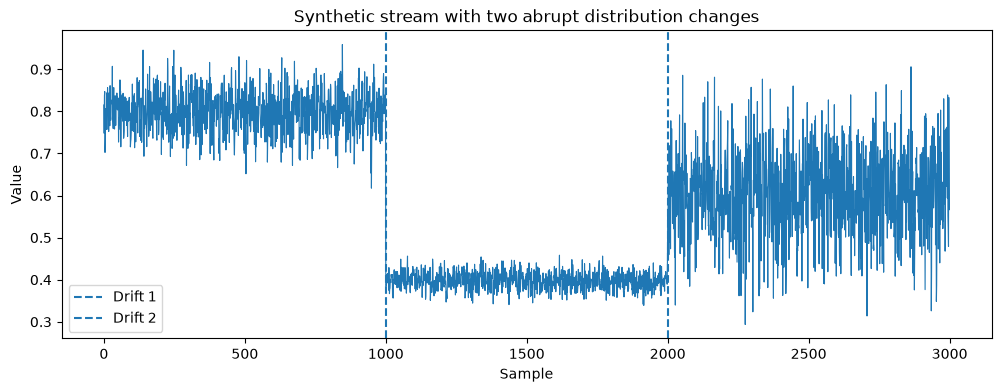

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Generate three distributions and concatenate them to simulate two abrupt drifts.
rng = np.random.default_rng(42)

dist_a = rng.normal(0.8, 0.05, 1000)
dist_b = rng.normal(0.4, 0.02, 1000)
dist_c = rng.normal(0.6, 0.10, 1000)

stream = np.concatenate((dist_a, dist_b, dist_c))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(stream, linewidth=0.8)
ax.axvline(1000, linestyle="--", label="Drift 1")
ax.axvline(2000, linestyle="--", label="Drift 2")
ax.set_xlabel("Sample")
ax.set_ylabel("Value")
ax.set_title("Synthetic stream with two abrupt distribution changes")
ax.legend()
plt.show()


As observed above, the synthetic data stream has 3 **abrupt drifts**. An analogy could be trending topics on social media which can change quickly.

The goal is to detect that drift has occurred, after samples **1000** and **2000** in the synthetic data stream.

In this example, we will use the Adaptive WINdowing (`ADWIN`) drift detection method.



In [30]:
from river import drift

drift_detector = drift.ADWIN()
drifts = []

for i, value in enumerate(stream):
    drift_detector.update(value)

    if drift_detector.drift_detected:
        print(f"Drift detected at index {i}")
        drifts.append(i)

Drift detected at index 1023
Drift detected at index 2047


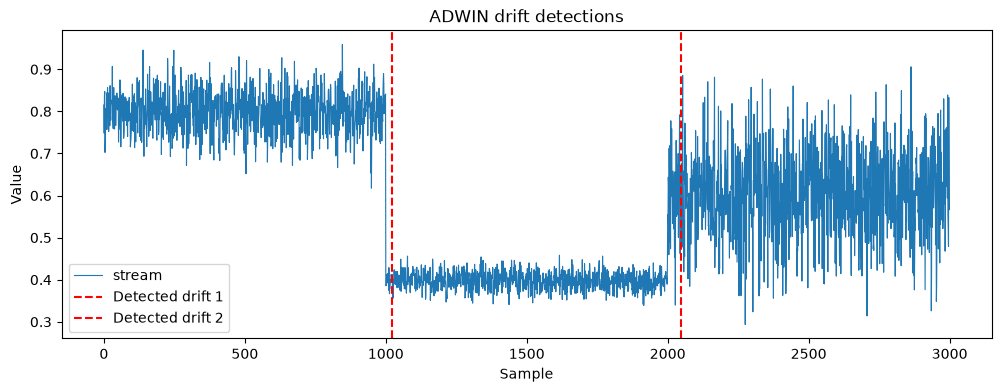

In [31]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(stream, linewidth=0.8, label="stream")

for i, drift_idx in enumerate(drifts, start=1):
    ax.axvline(drift_idx, linestyle="--", label=f"Detected drift {i}", color='red')

ax.set_xlabel("Sample")
ax.set_ylabel("Value")
ax.set_title("ADWIN drift detections")
ax.legend()
plt.show()


### Impact on predictive performance

Concept drift can negatively impact learning methods if not properly handled. Multiple real-world applications suffer **model degradation** as the models can not adapt to changes in the data.

In this example, we will use two popular streaming models:

1. The `Hoeffding Tree`
2. The `Hoeffding Adaptive Tree`

The `Hoeffding Adaptive Tree` uses `ADWIN` to detect changes. If change is detected in a given branch, an alternate branch is created and eventually replaces the original branch if it shows better performance on new data.

We will load the data from a csv file. The data was generated using the `AGRAWAL` data generator with 3 **gradual drifts** at the 5k, 10k, and 15k marks.

---
### `AGRAWAL` dataset

Obtained using a synthetic data generator, contains 9 features, 6 numeric and 3 categorical.

There are 10 functions for generating binary class labels from the features. These functions determine whether a **loan** should be approved.

| Feature    | Description            | Values                                                                |
|------------|------------------------|-----------------------------------------------------------------------|
| `salary`     | salary                 | uniformly distributed from 20k to 150k                                |
| `commission` | commission             | if (salary <   75k) then 0 else uniformly distributed from 10k to 75k |
| `age`        | age                    | uniformly distributed from 20 to 80                                   |
| `elevel`     | education level        | uniformly chosen from 0 to 4                                          |
| `car`        | car maker              | uniformly chosen from 1 to 20                                         |
| `zipcode`    | zip code of the town   | uniformly chosen from 0 to 8                                          |
| `hvalue`     | value of the house     | uniformly distributed from 50k x zipcode to 100k x zipcode            |
| `hyears`     | years house owned      | uniformly distributed from 1 to 30                                    |
| `loan`       | total loan amount      | uniformly distributed from 0 to 500k                                  |

**Class:** `y` | 0: no loan, 1: loan
 
**Samples:** 20,000

`elevel`, `car`, and `zipcode` are categorical features.

---### Impact on predictive performance

Concept drift can negatively impact learning methods if not properly handled. Multiple real-world applications suffer **model degradation** as the models can not adapt to changes in the data.

In this example, we will use two popular streaming models:

1. The `Hoeffding Tree`
2. The `Hoeffding Adaptive Tree`

The `Hoeffding Adaptive Tree` uses `ADWIN` to detect changes. If change is detected in a given branch, an alternate branch is created and eventually replaces the original branch if it shows better performance on new data.

We will load the data from a csv file. The data was generated using the `AGRAWAL` data generator with 3 **gradual drifts** at the 5k, 10k, and 15k marks.

---
### `AGRAWAL` dataset

Obtained using a synthetic data generator, contains 9 features, 6 numeric and 3 categorical.

There are 10 functions for generating binary class labels from the features. These functions determine whether a **loan** should be approved.

| Feature    | Description            | Values                                                                |
|------------|------------------------|-----------------------------------------------------------------------|
| `salary`     | salary                 | uniformly distributed from 20k to 150k                                |
| `commission` | commission             | if (salary <   75k) then 0 else uniformly distributed from 10k to 75k |
| `age`        | age                    | uniformly distributed from 20 to 80                                   |
| `elevel`     | education level        | uniformly chosen from 0 to 4                                          |
| `car`        | car maker              | uniformly chosen from 1 to 20                                         |
| `zipcode`    | zip code of the town   | uniformly chosen from 0 to 8                                          |
| `hvalue`     | value of the house     | uniformly distributed from 50k x zipcode to 100k x zipcode            |
| `hyears`     | years house owned      | uniformly distributed from 1 to 30                                    |
| `loan`       | total loan amount      | uniformly distributed from 0 to 500k                                  |

**Class:** `y` | 0: no loan, 1: loan
 
**Samples:** 20,000

`elevel`, `car`, and `zipcode` are categorical features.

---

In [32]:
from river.tree import HoeffdingTreeClassifier
from river.evaluate import progressive_val_score
from river.stream import iter_pandas
from river.metrics import Accuracy

import pandas as pd

data = pd.read_csv("agr_a_20k.csv")
features = data.columns[:-2]
stream = iter_pandas(X=data[features], y=data['class'])
model = HoeffdingTreeClassifier(nominal_attributes=['elevel', 'car', 'zipcode'])
metric = Accuracy()

progressive_val_score(dataset=stream,
                      model=model,
                      metric=metric,
                      print_every=1000)

[1,000] Accuracy: 82.08%
[2,000] Accuracy: 82.64%
[3,000] Accuracy: 83.79%
[4,000] Accuracy: 85.65%
[5,000] Accuracy: 86.50%
[6,000] Accuracy: 81.51%
[7,000] Accuracy: 79.20%
[8,000] Accuracy: 78.11%
[9,000] Accuracy: 78.49%
[10,000] Accuracy: 79.05%
[11,000] Accuracy: 77.47%
[12,000] Accuracy: 76.45%
[13,000] Accuracy: 75.91%
[14,000] Accuracy: 75.85%
[15,000] Accuracy: 75.95%
[16,000] Accuracy: 74.53%
[17,000] Accuracy: 73.58%
[18,000] Accuracy: 73.04%
[19,000] Accuracy: 72.67%
[20,000] Accuracy: 72.50%


Accuracy: 72.50%

In [33]:
from river.tree import HoeffdingAdaptiveTreeClassifier
from river.stream import iter_pandas
from river.metrics import Accuracy

import pandas as pd

data = pd.read_csv("agr_a_20k.csv")
features = data.columns[:-2]
stream = iter_pandas(X=data[features], y=data['class'])
model = HoeffdingAdaptiveTreeClassifier(nominal_attributes=['elevel', 'car', 'zipcode'], seed=42)
metric = Accuracy()

progressive_val_score(dataset=stream, model=model, metric=metric, print_every=1000)

[1,000] Accuracy: 83.28%
[2,000] Accuracy: 87.19%
[3,000] Accuracy: 88.60%
[4,000] Accuracy: 89.97%
[5,000] Accuracy: 90.44%
[6,000] Accuracy: 85.03%
[7,000] Accuracy: 82.01%
[8,000] Accuracy: 79.51%
[9,000] Accuracy: 77.70%
[10,000] Accuracy: 76.19%
[11,000] Accuracy: 75.79%
[12,000] Accuracy: 76.51%
[13,000] Accuracy: 77.24%
[14,000] Accuracy: 78.06%
[15,000] Accuracy: 78.75%
[16,000] Accuracy: 77.96%
[17,000] Accuracy: 77.96%
[18,000] Accuracy: 78.17%
[19,000] Accuracy: 78.27%
[20,000] Accuracy: 78.32%


Accuracy: 78.32%